# 50 — Thesis figures, Part II (Design space)

This notebook draws every figure and table of this part of the thesis and writes them, as PDF (for the thesis), PNG and CSV, to
`thesis_figures_v2/Part_II_design_space/<group>/<role>/`. Run it top to bottom; every cell shows exactly the file that was written.

| group | role | file | kind | what it shows |
|---|---|---|---|---|
| II1. Varying attributes | main | `q6_selected_fields` | table | Dimensions that tell designs apart |
| II1. Varying attributes | auxiliary | `q6_propulsor_units_per_class` | figure | Propulsor units per design, by architecture |
| II1. Varying attributes | appendix | `q6_arrangement_by_class` | figure | Arrangement features per architecture |
| II1. Varying attributes | appendix | `q6_ducting_by_units` | figure | Ducting per propulsor-unit band |
| II2. Levels of description | main | `q7_levels_of_description` | table | The three levels of description |
| II3. Distribution and new variety | main | `q6_configuration_core` | figure | Crowded core and empty rim |
| II3. Distribution and new variety | main | `q6_discovery_curve` | figure | Is the design space still opening |
| II3. Distribution and new variety | auxiliary | `q6_half_of_cohort` | figure | Configurations that hold half of a cohort's designs |

**Roles:** *main* goes in the chapter, *auxiliary* backs a statement of the chapter, *appendix* goes to the appendix.

## Where the numbers come from

- **The patent dataset** (627 designs): the author's characterisation of the patent drawings, read through `viz/thesis_q6.py` and `thesis_q7.py` unchanged. This notebook only draws.
- No external input: every number of Part II comes from the patent dataset itself.
- **Terms used in the figures:** configuration (a combination of attributes), assignee (who filed), cohort (a window of priority years); levels of description C = architecture, C·W·T = architecture, number of wings and whether any propulsor tilts, C·U = architecture and propulsor-unit band.

## Look and layout rules

Every figure is drawn under the author's thesis style, `viz/part1.mplstyle` (style 1, chosen 2026-10-12 among five in `viz/style_options/`):
Arial-type sans (Liberation Sans here), 9 pt labels, 8 pt ticks and legends, no top or right frame, a light horizontal grid, 6.3 in wide, PDF with embedded fonts.

The rules each figure is held to, and checked against in this notebook (`viz/figcheck.py`):

1. **No text on top of other text or of a mark.** Checked automatically: the check table at the end must read 0.
2. **Anything in columns is placed at fixed positions, never padded with spaces** (for example a numbered key), so rows line up exactly.
3. **One grid per plot**: a right-hand second axis draws no grid of its own.
4. **Words, not codes**: every abbreviation in a figure is spelled out in the figure or its key.
5. **No title inside the figure**: the caption in the thesis carries it.
6. **Nothing under 6.5 pt** at print size. Checked automatically.

## Setup

In [1]:
import sys, pathlib, importlib
PILLAR = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(PILLAR))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from viz import config, thesis, figcheck
v2 = importlib.import_module('viz.thesis_v2_part2')
cfg = config.load()
ctx = thesis.context(cfg)
OUT = v2.out_root(cfg)
print(len(ctx.v), 'designs | external inputs:', cfg.analysis.get('external_inputs', 'script'), '| writing to', OUT)
CHECKS = []

def show(name):
    """Build the item once under the thesis style, write it, check its layout, and show the written file."""
    it = next(i for i in v2.ITEMS if i['name'] == name)
    obj, data = v2.save_v2_item(it, cfg, ctx)
    folder = OUT / it['group'] / it['role']
    if it['kind'] == 'figure':
        ov, small = figcheck.overlaps(obj), figcheck.small_text(obj)
        CHECKS.append({'file': name, 'group': it['group'], 'role': it['role'], 'text over text': len(ov), 'under 6.5 pt': len(small),
                       'problems': '; '.join(f'{a} | {b}' for a, b in ov[:3])})
        plt.close('all')
        display(Image(filename=str(folder / f'{name}.png'), width=760))
        print(('layout OK' if not ov and not small else f'CHECK: {len(ov)} overlaps, {len(small)} small texts {ov[:3]} {small[:3]}'),
              '|', folder / f'{name}.pdf')
    else:
        CHECKS.append({'file': name, 'group': it['group'], 'role': it['role'], 'text over text': '', 'under 6.5 pt': '', 'problems': 'table'})
        display(obj)
        print(folder / f'{name}.csv')

627 designs | external inputs: script | writing to /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_II_design_space


/home/vasco/Vasco Workspace/Tese_Vasco_Lnx/eVTOL-Visual-Evaluation/labeling_evaluation/viz/frames.py:560: UserWarning: rapidfuzz not installed — fuzzy company matching disabled. Only exact lookup table matches will be applied.
  canon = g._normalise_company(sraw)


## II1. Varying attributes

*Which dimensions tell designs apart, and how do propulsor number and ducting vary by architecture?*

### Dimensions that tell designs apart

`q6_selected_fields` · main · table · from v2 of q6_selected_fields (Table 6)

In [2]:
show('q6_selected_fields')

,dimension,designs answering,options,top share,most common options
0,propulsor units per design (band),595,5,23 %,1–3: 136 · 4: 125 · 5–6: 117 · 9+: 117 · 7–8: 100
1,tail type,600,13,29 %,Tailless: 176 · Conventional: 74 · V-tail: 69 ...
2,places carrying propulsor units per design,595,4,48 %,2: 286 · 1: 246 · 3: 60 · 4 or more: 3
3,number of wings (winged designs),547,3,66 %,1: 359 · 2: 172 · 3: 16
4,landing-gear type,602,3,68 %,Unknown: 411 · Wheeled: 101 · Skids: 90
5,fuselage motion hover to cruise,602,4,85 %,Fixed: 511 · Whole-body pitch: 62 · Tail-sitte...
6,wing configuration,541,5,87 %,Standard: 471 · Other: 49 · Blended wing body:...


/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_II_design_space/II1_varying_attributes/main/q6_selected_fields.csv


### Propulsor units per design, by architecture

`q6_propulsor_units_per_class` · auxiliary · figure · from v2 of q6_propulsor_units_per_class (Figure 6 (i))

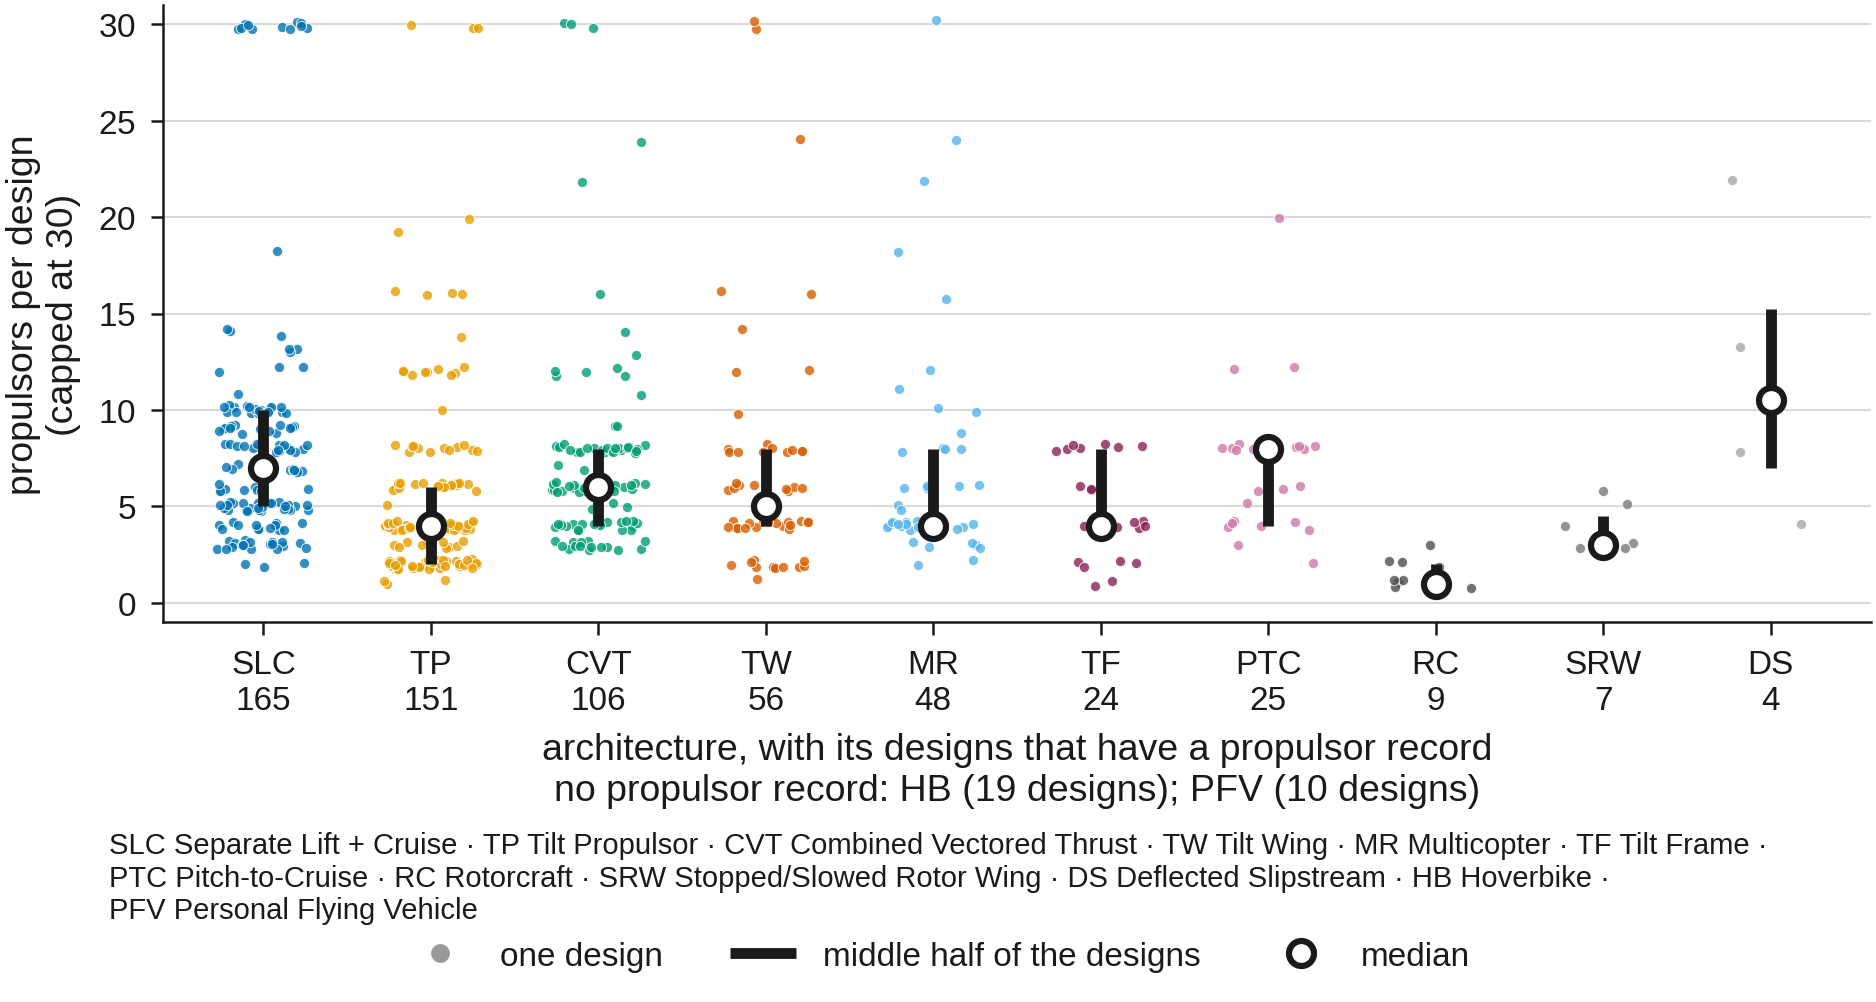

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_II_design_space/II1_varying_attributes/auxiliary/q6_propulsor_units_per_class.pdf


In [3]:
show('q6_propulsor_units_per_class')

### Arrangement features per architecture

`q6_arrangement_by_class` · appendix · figure · from v2 of q6_arrangement_by_class

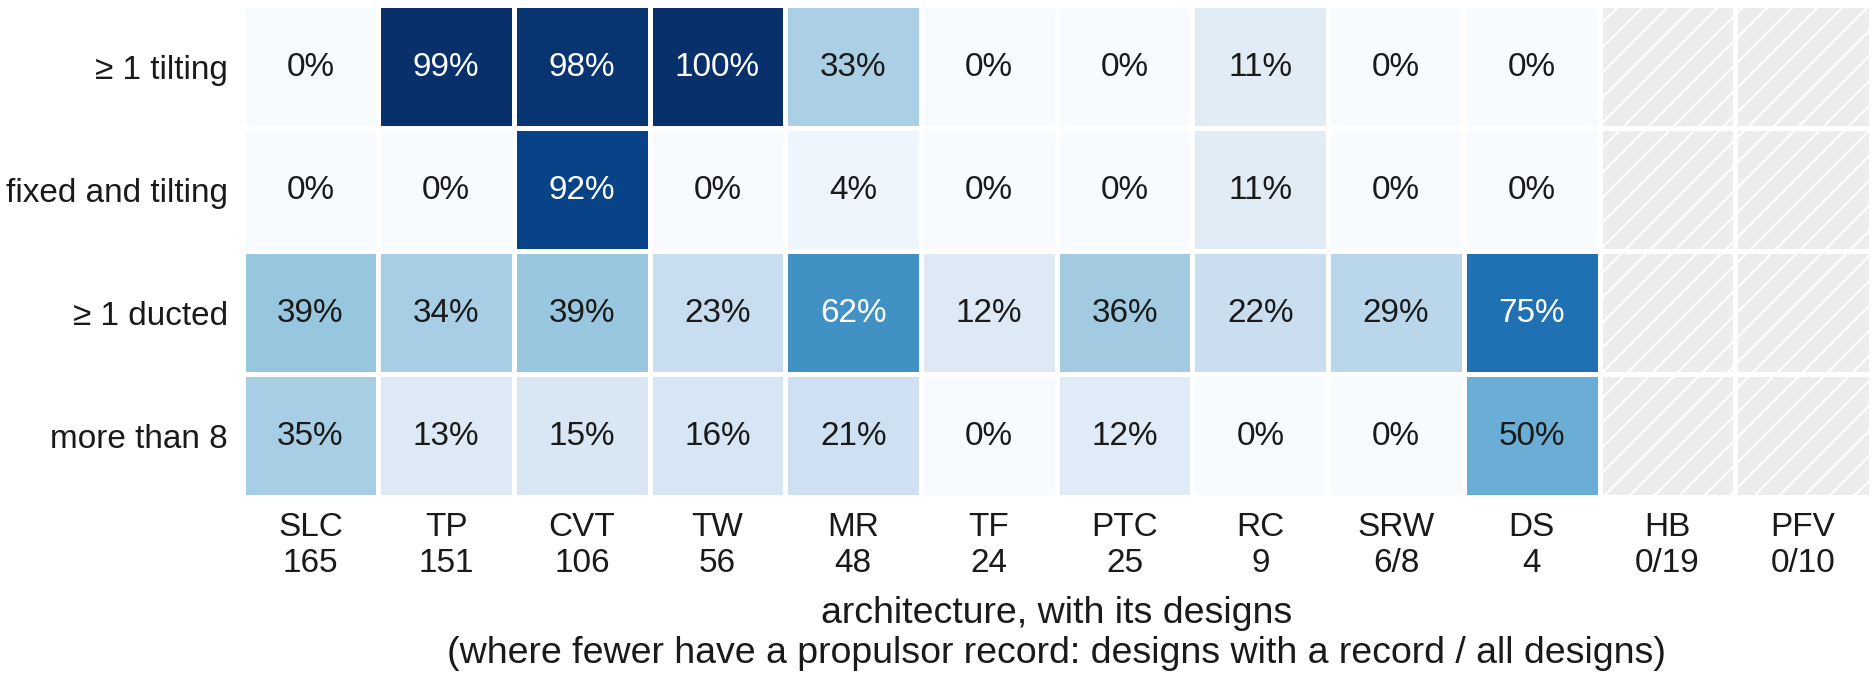

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_II_design_space/II1_varying_attributes/appendix/q6_arrangement_by_class.pdf


In [4]:
show('q6_arrangement_by_class')

### Ducting per propulsor-unit band

`q6_ducting_by_units` · appendix · figure · from v2 of q6_ducting_by_units

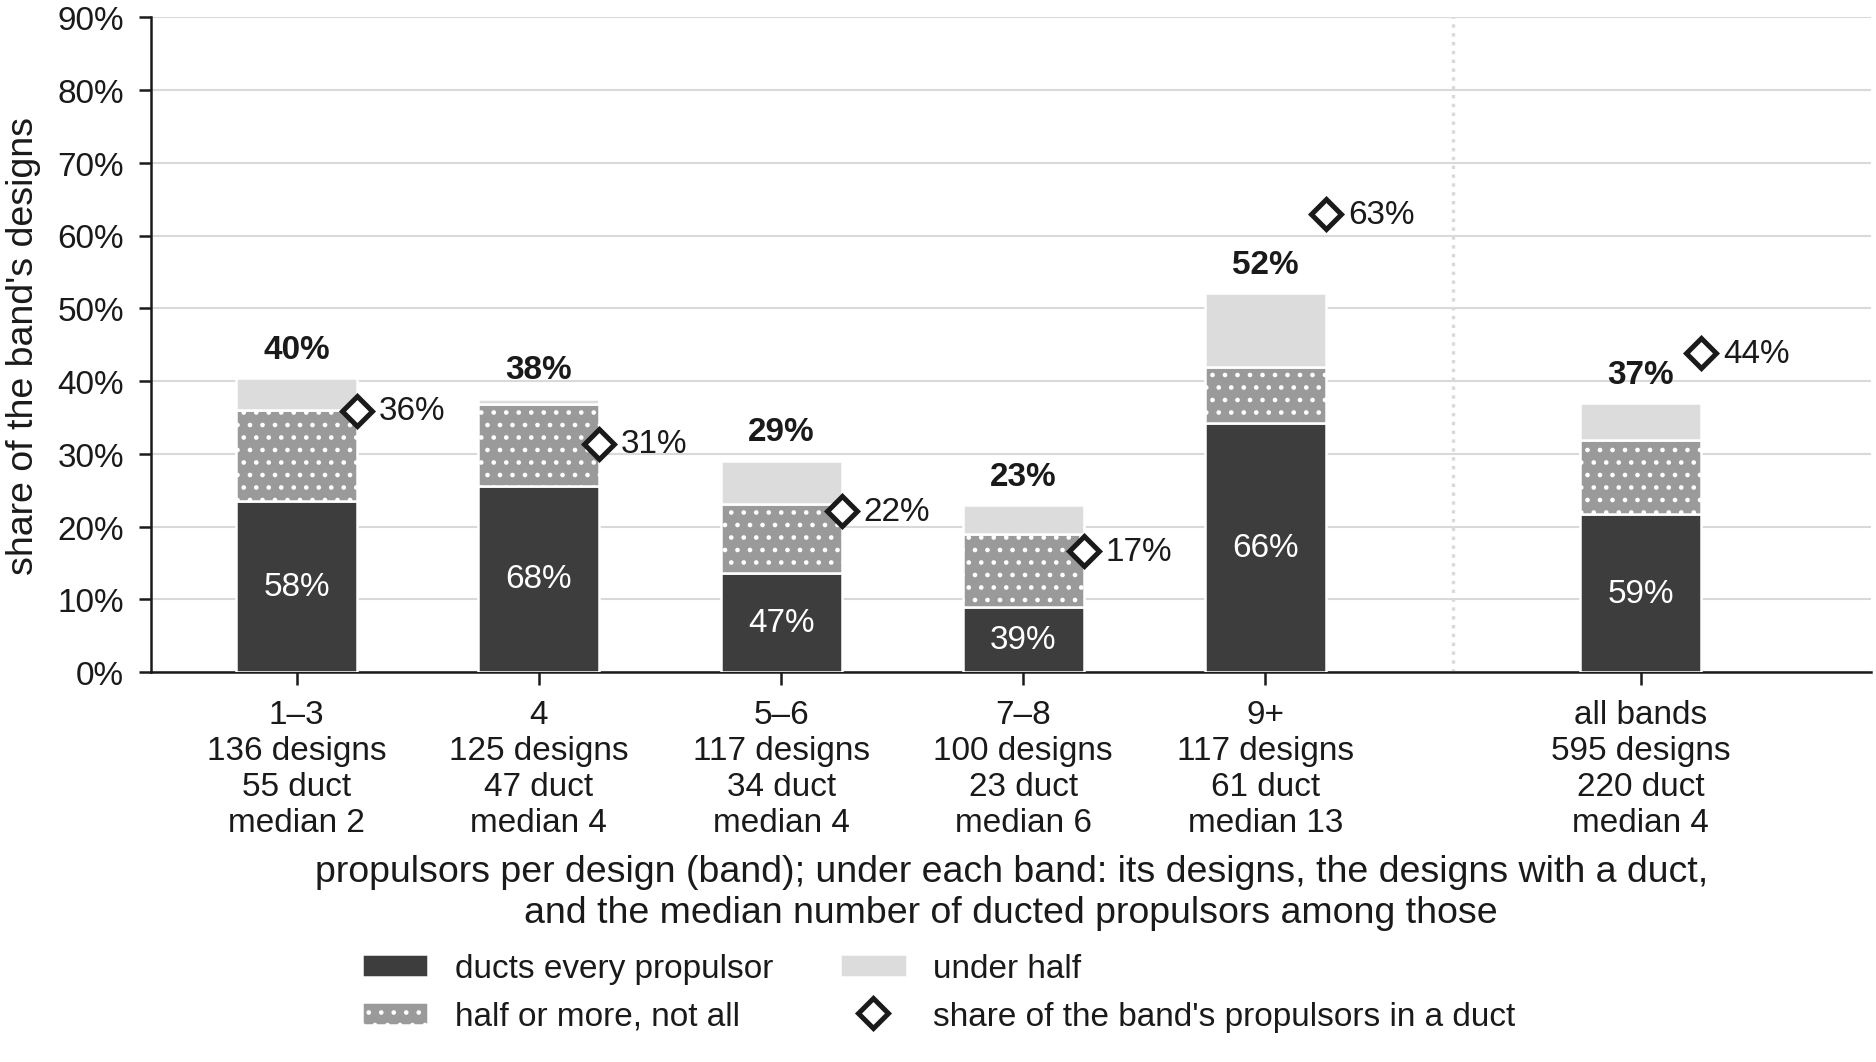

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_II_design_space/II1_varying_attributes/appendix/q6_ducting_by_units.pdf


In [5]:
show('q6_ducting_by_units')

## II2. Levels of description

*How many configurations does each level of description give: C (architecture), C·W·T (architecture, wings and tilt), C·U (architecture and propulsor units)?*

### The three levels of description

`q7_levels_of_description` · main · table · from v2 of q7_archetype_sets (Table 7), F row removed

In [6]:
show('q7_levels_of_description')

,level,configurations,singletons,¹D,largest configuration,its share
0,A,12,0,7.3,SLC,26 %
1,A·W·T,39,10,16.4,SLC · one wing · no tilting propulsor,17 %
2,A·U,43,3,29.3,TP · 1–3 propulsor units,10 %


/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_II_design_space/II2_levels_of_description/main/q7_levels_of_description.csv


## II3. Distribution and new variety

*How are the designs spread over the configurations, and is new variety still appearing?*

### Crowded core and empty rim

`q6_configuration_core` · main · figure · from v2 of q6_archetype_core (Figure 8 (i))

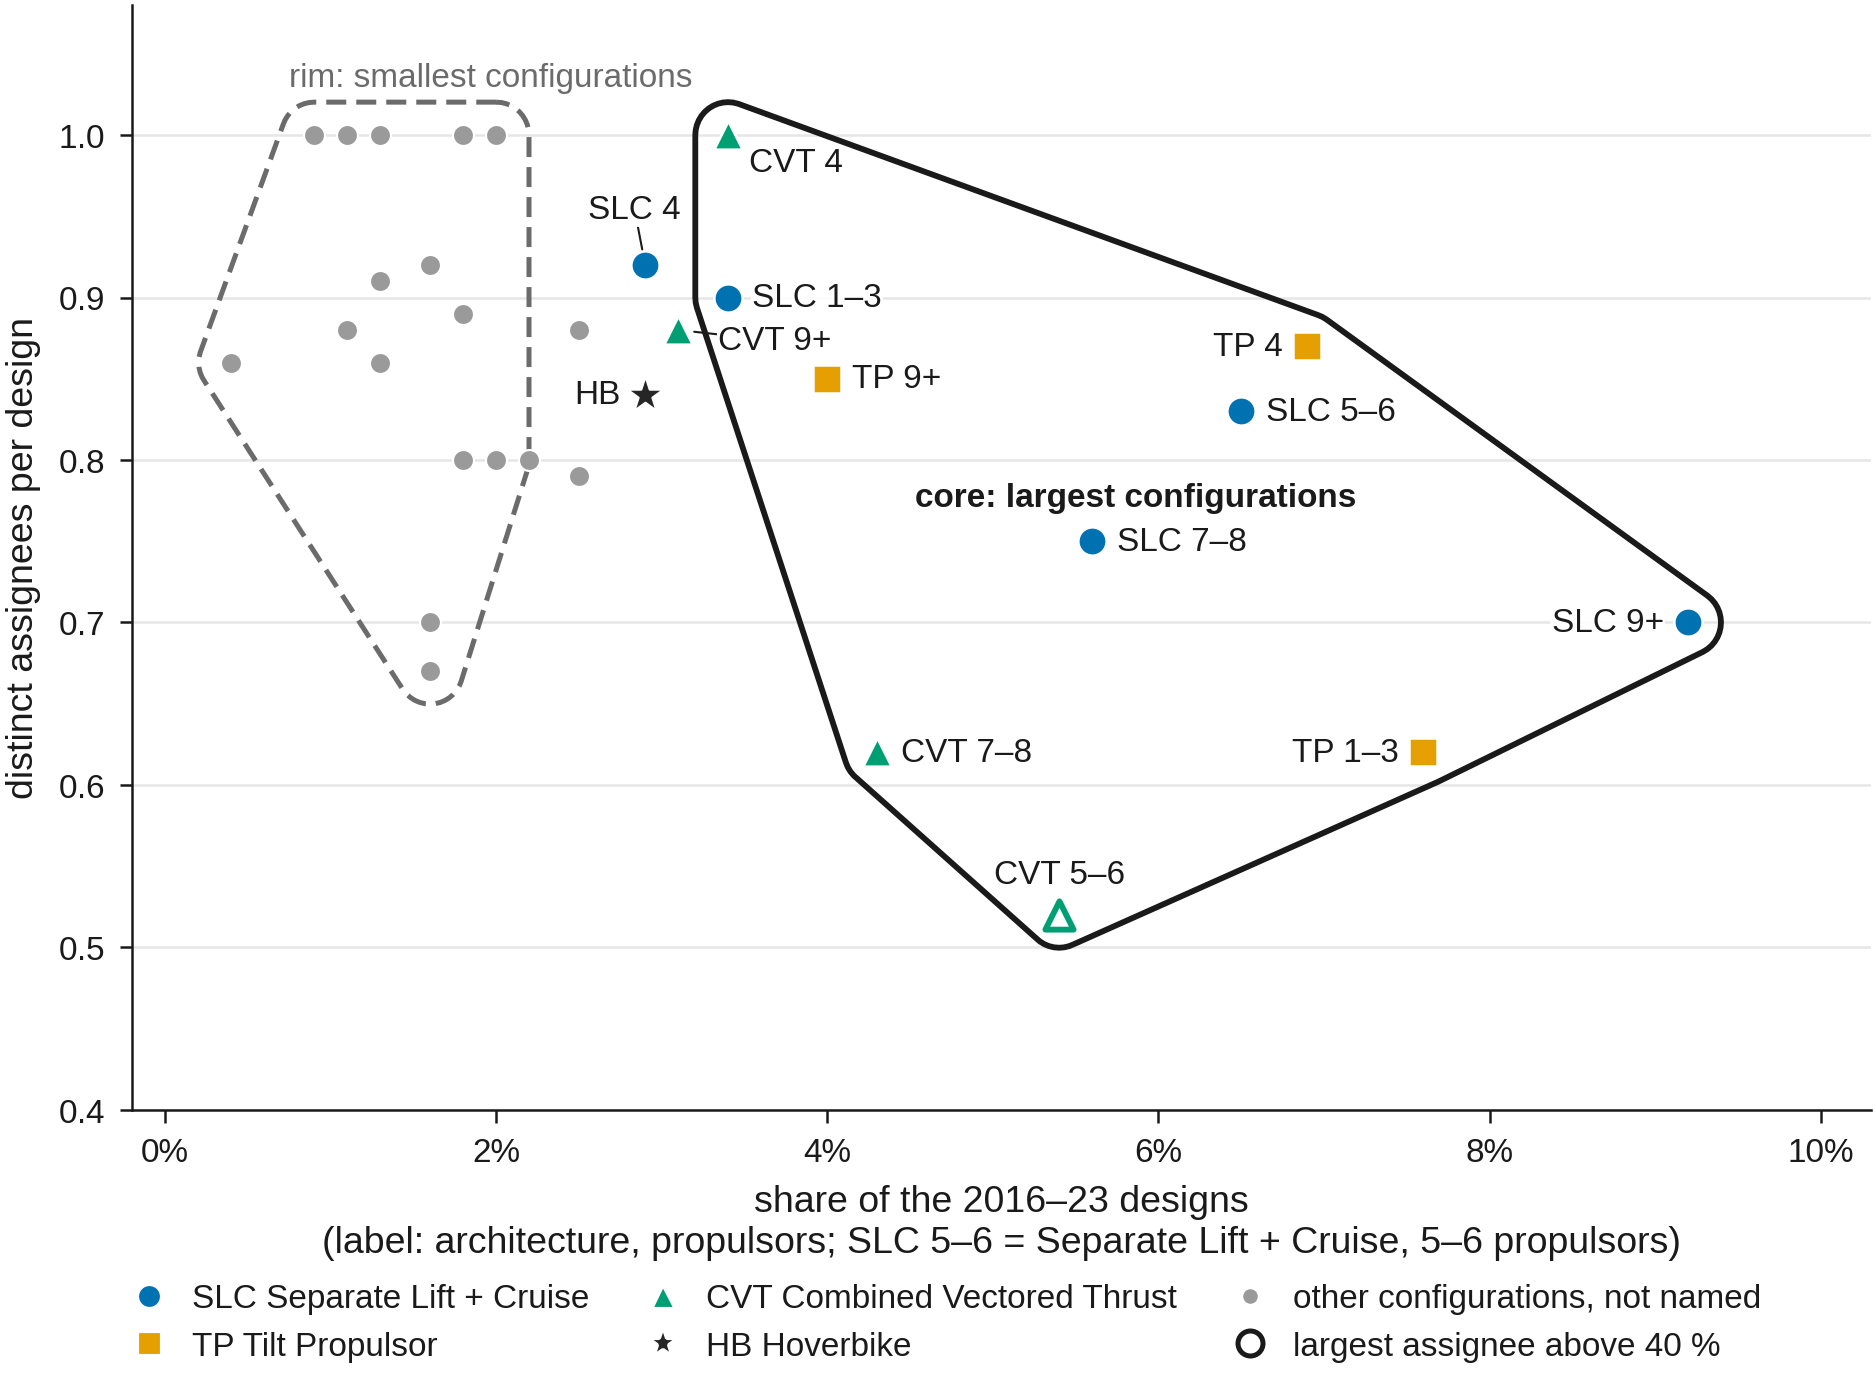

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_II_design_space/II3_distribution_and_new_variety/main/q6_configuration_core.pdf


In [7]:
show('q6_configuration_core')

### Is the design space still opening

`q6_discovery_curve` · main · figure · from v2 of q6_discovery_curve (Figure 9)

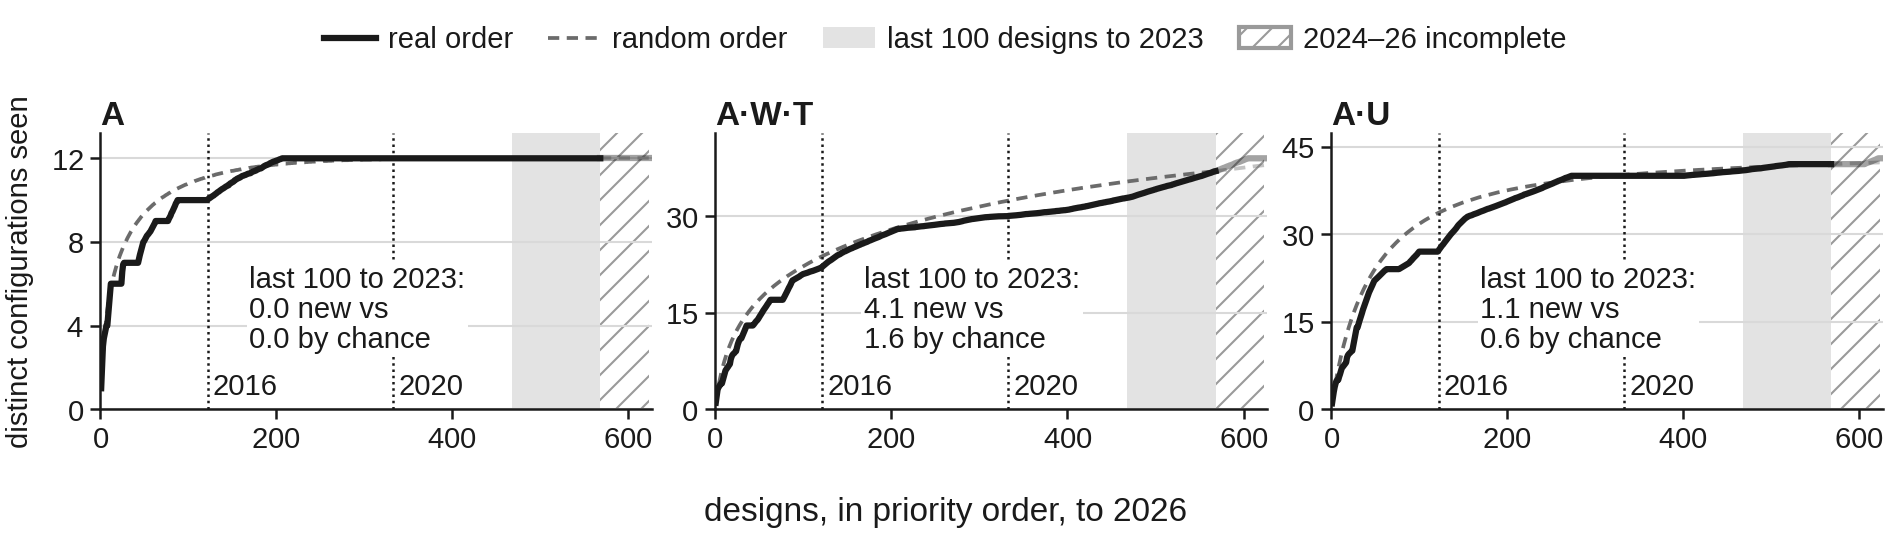

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_II_design_space/II3_distribution_and_new_variety/main/q6_discovery_curve.pdf


In [8]:
show('q6_discovery_curve')

### Configurations that hold half of a cohort's designs

`q6_half_of_cohort` · auxiliary · figure · from replaces q6_archetype_windows (Figure 8 (ii))

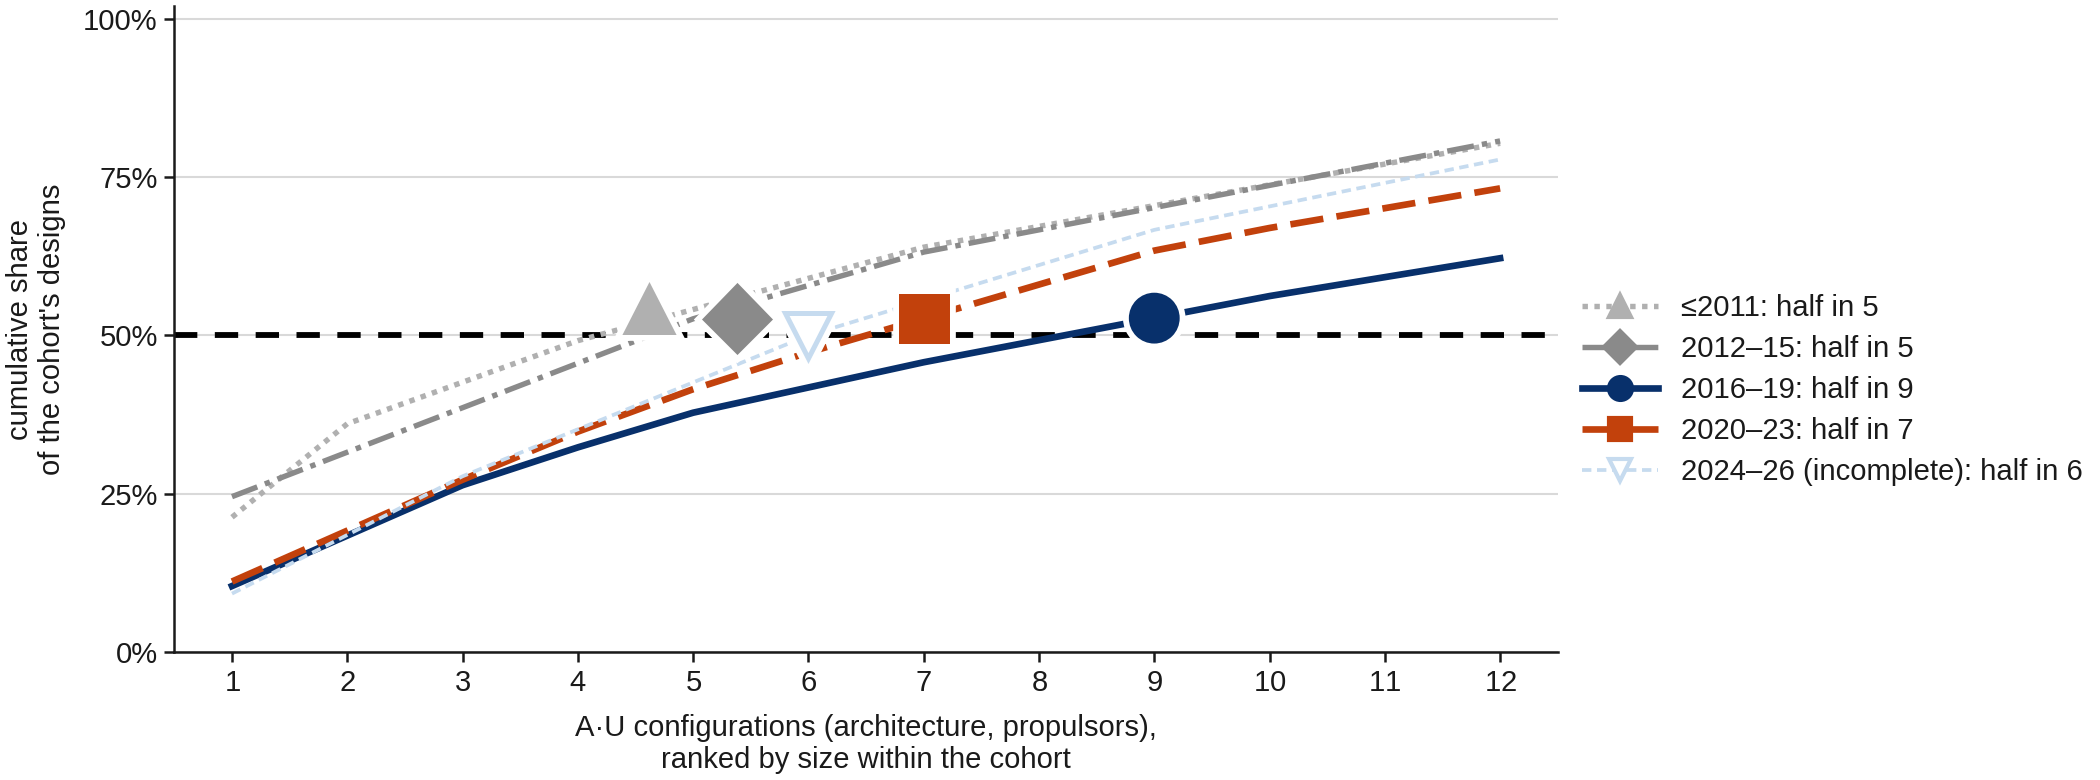

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_II_design_space/II3_distribution_and_new_variety/auxiliary/q6_half_of_cohort.pdf


In [9]:
show('q6_half_of_cohort')

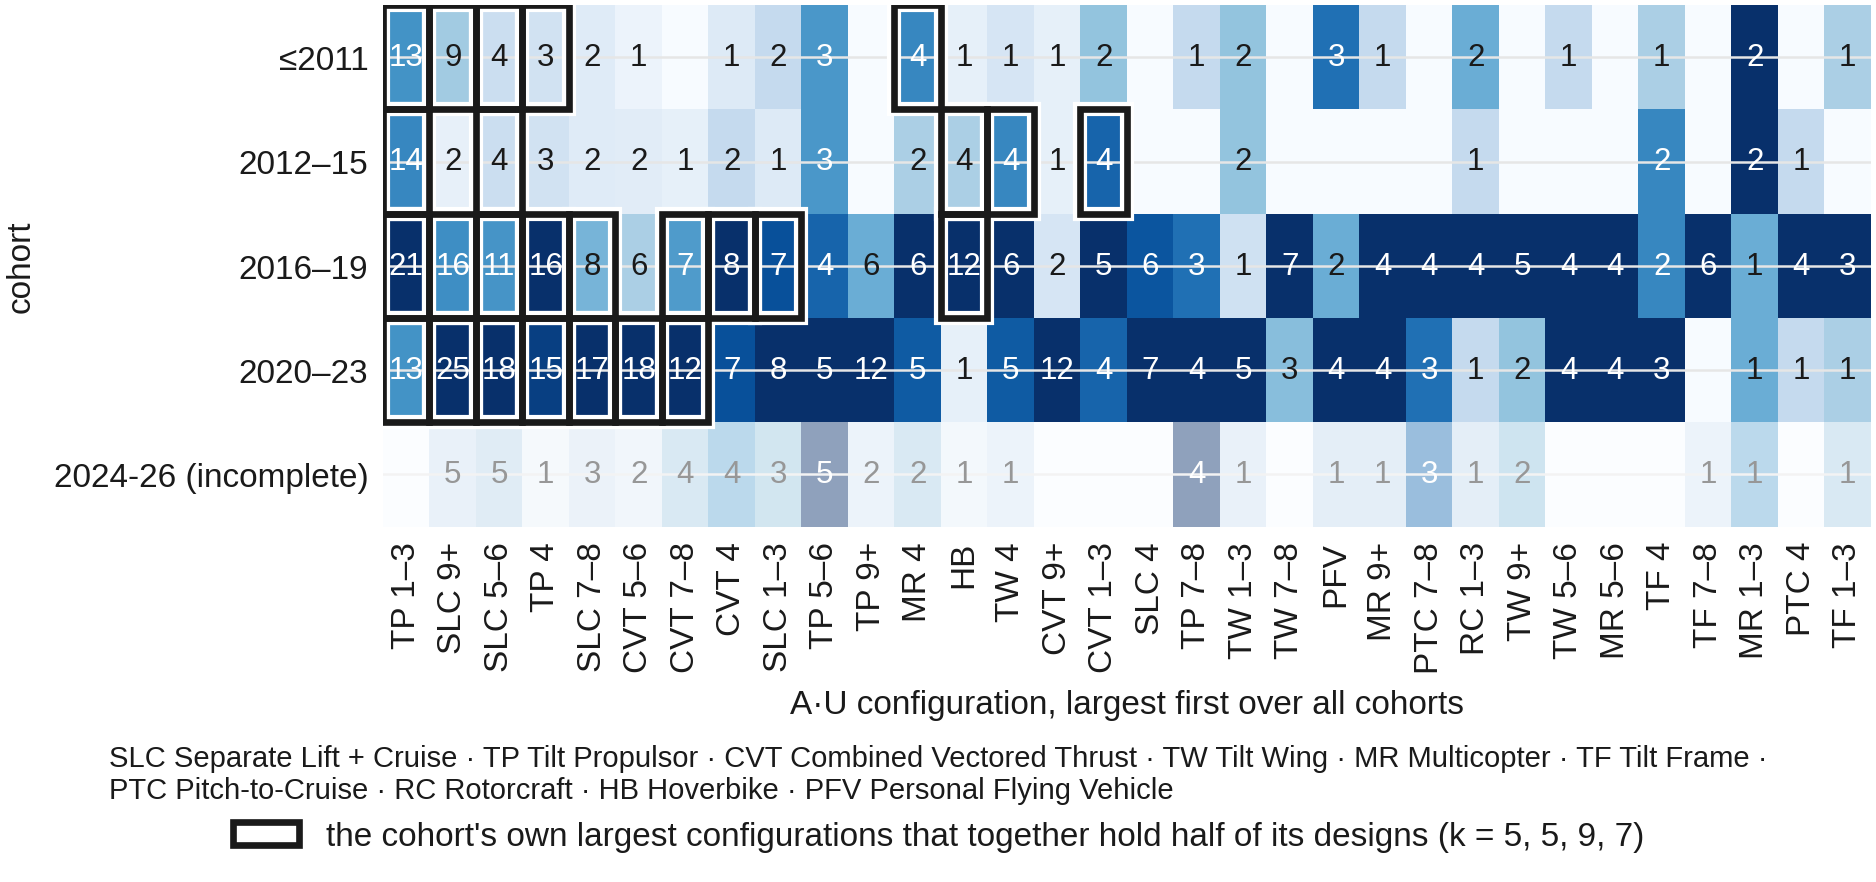

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_II_design_space/II3_distribution_and_new_variety/auxiliary/q6_half_of_cohort_heatmap.pdf


In [10]:
show('q6_half_of_cohort_heatmap')

## Layout check, all figures

Every row should read 0 and 0. A row that does not names the texts that collide.

In [11]:
chk = pd.DataFrame(CHECKS)
display(chk)
figs = chk[chk['problems'] != 'table']
print('all figures pass' if (figs['text over text'] == 0).all() and (figs['under 6.5 pt'] == 0).all() else 'SOME FIGURES NEED A FIX (see the table)')

,file,group,role,text over text,under 6.5 pt,problems
0,q6_selected_fields,II1_varying_attributes,main,,,table
1,q6_propulsor_units_per_class,II1_varying_attributes,auxiliary,0,0,
2,q6_arrangement_by_class,II1_varying_attributes,appendix,0,0,
3,q6_ducting_by_units,II1_varying_attributes,appendix,0,0,
4,q7_levels_of_description,II2_levels_of_description,main,,,table
5,q6_configuration_core,II3_distribution_and_new_variety,main,0,0,
6,q6_discovery_curve,II3_distribution_and_new_variety,main,0,0,
7,q6_half_of_cohort,II3_distribution_and_new_variety,auxiliary,0,0,
8,q6_half_of_cohort_heatmap,II3_distribution_and_new_variety,auxiliary,0,0,


all figures pass


## README and file list

Rewrite the folder's README.md and list every file written.

In [12]:
import subprocess
print(subprocess.run([sys.executable, str(PILLAR / 'notebooks' / '_build' / 'write_readme_50.py')], capture_output=True, text=True).stdout)
files = sorted(p.relative_to(OUT) for p in OUT.rglob('*') if p.is_file())
print(len(files), 'files'); files

written /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_II_design_space/README.md
- configurations at C / C·W·T / C·U: **12 / 39 / 43** — thesis 12 / 39 / 43: matches
- ¹D at C / C·W·T / C·U: **7.3 / 16.4 / 29.3** — thesis 7.3 / 16.4 / 29.4: **DOES NOT MATCH**
- core: **10** configurations holding **56.3 %** of the 2016–23 designs — thesis 7 and 45 %: **DOES NOT MATCH**
- configurations that hold half of a cohort, **ranked by size within the cohort** (the new figure): 2016–19 **9**, 2020–23 **7**; read in the thesis's column order (the C·U configurations ranked by their size over all years, as the original heatmap and `frames.half_column` do): 2016–19 **10**, 2020–23 **7** — thesis 10 and 7: 2016–19 matches in the thesis's ordering but is **9** when ranked within the cohort (the text and the figure differ by one); 2020–23 matches in both
- last 100 designs at C·W·T: *

[PosixPath('II1_varying_attributes/appendix/q6_arrangement_by_class.csv'),
 PosixPath('II1_varying_attributes/appendix/q6_arrangement_by_class.json'),
 PosixPath('II1_varying_attributes/appendix/q6_arrangement_by_class.pdf'),
 PosixPath('II1_varying_attributes/appendix/q6_arrangement_by_class.png'),
 PosixPath('II1_varying_attributes/appendix/q6_ducting_by_units.csv'),
 PosixPath('II1_varying_attributes/appendix/q6_ducting_by_units.json'),
 PosixPath('II1_varying_attributes/appendix/q6_ducting_by_units.pdf'),
 PosixPath('II1_varying_attributes/appendix/q6_ducting_by_units.png'),
 PosixPath('II1_varying_attributes/auxiliary/q6_propulsor_units_per_class.csv'),
 PosixPath('II1_varying_attributes/auxiliary/q6_propulsor_units_per_class.json'),
 PosixPath('II1_varying_attributes/auxiliary/q6_propulsor_units_per_class.pdf'),
 PosixPath('II1_varying_attributes/auxiliary/q6_propulsor_units_per_class.png'),
 PosixPath('II1_varying_attributes/main/q6_selected_fields.csv'),
 PosixPath('II1_varying

## Hand-over to the dissertation (LaTeX_v15)

Analysis II: `q6_configuration_core` (0.9 of the 16 cm text block), `q6_discovery_curve` (1.0), `q6_propulsor_units_per_class` (0.8, appendix) and `q6_half_of_cohort` (1.0, text width, leaves the text; redrawn wide 2026-10-16), each drawn at its final width, height at most 55 % of the width, text 7 pt or more, no title; the data behind every figure and the three tables; `NUMBERS_II.md`; the manifest lines. Nothing is recomputed differently; the builders are those above.

In [13]:
from viz import thesis_latex_part2 as hand
chk = hand.export(cfg, ctx)
display(chk)
print('all pass' if (chk['text over text'] == 0).all() and (chk['under 7 pt'] == 0).all() and (chk['height / width'] <= 0.55).all() else 'FIX NEEDED')
print(hand.root(cfg))

,figure,width cm,height cm,height / width,text over text,under 7 pt
0,q6_configuration_core,14.40,7.92,0.550,0,0
1,q6_discovery_curve,15.88,4.52,0.285,0,0
2,q6_half_of_cohort_heatmap,16.00,8.80,0.550,0,0
3,q6_half_of_cohort,16.00,5.94,0.371,0,0
4,q6_propulsor_units_per_class,12.80,7.04,0.550,0,0


all pass
/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/LaTeX_v15


## Hand-over 2026-10-16 (Tasks 2 and 4)

Task 2: `q6_fixed_by_architecture` and `q6_fixed_by_architecture_detail` (`thesis_q6.fixed_by_architecture`: Bergsma-corrected Cramér's V of each of the seven dimensions of `q6_selected_fields` against the architecture, permutation p over 1 000 shuffles with seed 42, the leading option per architecture and how many architectures sit at 80 % or more). The export above wrote both csv to `Data_for_writing/csv/` and `Figures/Part_II_design_space/II1_varying_attributes/appendix/`, and the section of `NUMBERS_II.md`.
Task 4: `q6_half_of_cohort` redrawn wide (7 in by 2.6 in; 16 cm at the final width), first 12 configurations, thicker dashed 50 % line, crossing markers twice as large with a white edge.

This cell writes the other copies the hand-over asks for: png, csv and json beside the LaTeX_v15 pdf (drawn at the final width), the notebook-size (v2) copies under `LaTeX_v15/Figures/thesis_figures_v2/...`, the json of the tables beside their csv, and every file plus the changed scripts in `handoff_2026-10-16/` at the repository root.

In [14]:
from viz import handoff_2026_10_16 as ho, thesis_latex_part2 as hand
R = hand.root(cfg)
PART = 'Part_II_design_space'
written = []
for name in ('q6_fixed_by_architecture', 'q6_fixed_by_architecture_detail'):
    it = next(i for i in v2.ITEMS if i['name'] == name)
    written += ho.table_copies('task2', name, it, PART, OUT / it['group'] / it['role'], R,
                               also_to=R / 'Figures' / PART / it['group'] / it['role'])
written += ho.plain_copies('task2', [R / 'Data_for_writing' / 'NUMBERS_II.md'])
ho.copy_scripts('task2', ['lib/association.py', 'viz/frames.py', 'viz/thesis_q6.py', 'viz/thesis_v2_part2.py', 'viz/thesis_latex_part2.py',
                          'viz/handoff_2026_10_16.py', 'notebooks/50_thesis_figures_v2_part2.ipynb'])
name = 'q6_half_of_cohort'
it = next(i for i in v2.ITEMS if i['name'] == name)
written += ho.figure_copies('task4', name, it, PART, OUT / it['group'] / it['role'], R,
                            lambda: hand.draw(it, ctx, hand.FIGS[name][0])[:2])
ho.copy_scripts('task4', ['viz/thesis_v2_part2.py', 'viz/thesis_latex_part2.py', 'viz/handoff_2026_10_16.py', 'notebooks/50_thesis_figures_v2_part2.ipynb'])
print('\n'.join(map(str, written)))
print(ho.listing('task2') + ho.listing('task4'))

/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/LaTeX_v15/Figures/Part_II_design_space/II1_varying_attributes/appendix/q6_fixed_by_architecture.csv
/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/LaTeX_v15/Figures/Part_II_design_space/II1_varying_attributes/appendix/q6_fixed_by_architecture_detail.csv
/home/vasco/Vasco Workspace/Tese_Vasco_Lnx/eVTOL-Visual-Evaluation/handoff_2026-10-16/task2/NUMBERS_II.md
/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/LaTeX_v15/Figures/Part_II_design_space/II3_distribution_and_new_variety/auxiliary/q6_half_of_cohort.pdf
/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/LaT